# 3. Ajuste dos parâmetros do SVR

Mesmo procedimento do exemplo do professor (*Series Temporais Exp 04*, segunda parte), aplicado às nossas bases:

- entradas: os últimos `dimension` valores da série normalizada; saída: o valor do dia seguinte (`stepahead = 1`);
- **dimension**: o melhor lag de cada série, encontrado no notebook `01_analise_lags`;
- **busca em grade** com as mesmas faixas do professor:
  - `gamma` = 10⁻⁵ … 10² (8 valores)
  - `epsilon` = 10⁻⁴ … 10⁻² (3 valores)
  - `C` = 10⁻² … 10² (5 valores)

  Ao todo são 120 combinações por série, cada uma treinada no treino e avaliada pelo **MSE na validação**;
- o melhor SVR é avaliado no **teste** e comparado com o `SVR()` sem seleção de parâmetros (padrão do sklearn). Também comparamos com o modelo linear do notebook 01 e com o modelo ingênuo.

Divisão 60% / 20% / 20%, em ordem cronológica.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import mean_squared_error as mse
from matplotlib import pyplot as plt

# Lê as planilhas do repositório (pasta dados/). No Colab, busca direto no GitHub.
URL = "https://raw.githubusercontent.com/BerzinMiguel/IA.2026.2/main/dados/"

def ler_serie(arquivo, coluna):
    for pasta in (Path("dados"), Path("../dados")):
        if (pasta / arquivo).exists():
            return pd.read_excel(pasta / arquivo)[coluna].dropna().to_numpy(dtype=float)
    return pd.read_excel(URL + arquivo)[coluna].dropna().to_numpy(dtype=float)

bases = {
    "Dólar": ler_serie("Dolar_tratado.xlsx", "Valor"),
    "Petrobras": ler_serie("Petrobras_tratado.xlsx", "Valor"),
    "Volatilidade": ler_serie("volatilidade.xlsx", "Volatilidade_Diaria"),
}
for nome, serie in bases.items():
    print(f"{nome}: {len(serie)} dias")

trainSplit = 0.8   # usado para treinar o modelo
validSplit = 0.1   # verificar se o modelo é adequado (escolha de parâmetros)
                   # os 20% finais ficam para o teste

Dólar: 1724 dias
Petrobras: 1711 dias
Volatilidade: 1710 dias


In [ ]:
def preparar(dataset):
    """Normaliza com mínimo e máximo do TREINO, como no exemplo do professor."""
    trainSize = int(np.floor(trainSplit * len(dataset)))
    validSize = int(np.floor(validSplit * len(dataset)))
    maxData = np.max(dataset[0:trainSize])
    minData = np.min(dataset[0:trainSize])
    ndataset = (dataset - minData) / (maxData - minData)
    return pd.Series(ndataset), trainSize, validSize


def janelas(datasetSeries, dim, stepahead, trainSize, validSize):
    """Monta as janelas de lags (coluna 0 = alvo; colunas seguintes = passado).

    Com stepahead = 1 é exatamente o datasetShifted do professor. Para
    stepahead = h, as entradas são os valores de h até h+dim-1 dias antes do alvo.
    """
    datasetShifted = pd.concat([datasetSeries.shift(i) for i in range(dim + stepahead)], axis=1)
    entradas = datasetShifted.iloc[:, stepahead:]
    alvo = datasetShifted.iloc[:, 0]
    inicio = dim + stepahead - 1   # primeira linha sem valores vazios (= dim quando stepahead = 1)
    blocos = {
        "train": slice(inicio, trainSize),
        "valid": slice(trainSize, trainSize + validSize),
        "test": slice(trainSize + validSize, None),
    }
    return {nome: (entradas.iloc[b].values, alvo.iloc[b].values) for nome, b in blocos.items()}

In [ ]:
from sklearn.svm import SVR  # support vector regression

# Melhor lag de cada série, saído do notebook 01 (stepahead = 1)
MELHOR_LAG = {"Dólar": 1, "Petrobras": 1, "Volatilidade": 14}
stepahead = 1

g = (10.0) ** np.arange(-5, 3, 1)   # gamma
e = (10.0) ** np.arange(-4, -1, 1)  # epsilon
c = (10.0) ** np.arange(-2, 3, 1)   # C

## Busca em grade (igual ao exemplo, repetida para cada série)

In [ ]:
resultados, busca, curvas = [], [], {}

for nome, dataset in bases.items():
    datasetSeries, trainSize, validSize = preparar(dataset)
    dimension = MELHOR_LAG[nome]
    b = janelas(datasetSeries, dimension, stepahead, trainSize, validSize)
    (train, trainTarget), (valid, validTarget), (test, testTarget) = b["train"], b["valid"], b["test"]

    bestValue = 10**100000
    for i in g:
        for j in e:
            for k in c:
                mySVR = SVR(C=k, gamma=i, epsilon=j)
                mySVR.fit(train, trainTarget)
                predVals = mySVR.predict(valid)
                erro = mse(predVals, validTarget)
                busca.append({"série": nome, "gamma": i, "epsilon": j, "C": k, "MSE validação": erro})
                if erro < bestValue:
                    bestValue = erro
                    bestSVR = mySVR
                    bestParams = (i, j, k)

    predTest = bestSVR.predict(test)
    mseTest = mse(predTest, testTarget)

    SVR_no_Selection = SVR()
    SVR_no_Selection.fit(train, trainTarget)
    predTestNoSelection = SVR_no_Selection.predict(test)
    mseTest_noSelection = mse(predTestNoSelection, testTarget)

    # referências: modelo linear (pinv, notebook 01) e ingênuo (repete o último valor)
    um = lambda X: np.hstack((X, np.ones((len(X), 1))))
    coefs = np.linalg.pinv(um(train)).dot(trainTarget)
    mseLinear = mse(coefs.dot(um(test).T), testTarget)
    mseIngenuo = mse(test[:, 0], testTarget)

    curvas[nome] = (testTarget, predTest, predTestNoSelection)
    resultados.append({
        "série": nome, "dimension": dimension,
        "gamma": bestParams[0], "epsilon": bestParams[1], "C": bestParams[2],
        "MSE validação": bestValue,
        "MSE teste SVR_Best": mseTest,
        "MSE teste SVR_No_Selection": mseTest_noSelection,
        "MSE teste linear": mseLinear,
        "MSE teste ingênuo": mseIngenuo,
    })

resultados = pd.DataFrame(resultados)
busca = pd.DataFrame(busca)
colunas_mse = [col for col in resultados.columns if col.startswith("MSE teste")]
print("MSE na escala normalizada [0, 1] do treino")
(resultados.style
    .format({col: "{:.6f}" for col in resultados.columns if col.startswith("MSE")})
    .format({"gamma": "{:g}", "epsilon": "{:g}", "C": "{:g}"})
    .highlight_min(axis=1, subset=colunas_mse, color="#c6efce"))

MSE na escala normalizada [0, 1] do treino


,série,dimension,gamma,epsilon,C,MSE validação,MSE teste SVR_Best,MSE teste SVR_No_Selection,MSE teste linear,MSE teste ingênuo
0,Dólar,1,0.01,0.01,100,0.000485,0.000488,0.000614,0.000486,0.000490
1,Petrobras,1,1,0.001,1,0.000381,0.003317,0.106115,0.000660,0.000652
2,Volatilidade,14,0.01,0.01,100,0.001199,0.001230,0.005021,0.001308,0.002150


In [ ]:
# As 5 melhores combinações de cada série na validação
for nome in bases:
    print(nome)
    display(busca[busca["série"] == nome].nsmallest(5, "MSE validação").reset_index(drop=True))

Dólar


,série,gamma,epsilon,C,MSE validação
0,Dólar,0.010,0.0100,100.0,0.000485
1,Dólar,0.001,0.0001,100.0,0.000489
2,Dólar,0.001,0.0010,100.0,0.000490
3,Dólar,0.001,0.0100,100.0,0.000492
4,Dólar,0.010,0.0010,100.0,0.000492


Petrobras


,série,gamma,epsilon,C,MSE validação
0,Petrobras,1.0,0.0010,1.0,0.000381
1,Petrobras,1.0,0.0001,1.0,0.000381
2,Petrobras,0.1,0.0001,1.0,0.000384
3,Petrobras,1.0,0.0100,1.0,0.000384
4,Petrobras,0.1,0.0010,1.0,0.000385


Volatilidade


,série,gamma,epsilon,C,MSE validação
0,Volatilidade,0.01,0.0100,100.0,0.001199
1,Volatilidade,0.01,0.0001,100.0,0.001203
2,Volatilidade,0.01,0.0010,100.0,0.001204
3,Volatilidade,0.10,0.0100,1.0,0.001206
4,Volatilidade,0.10,0.0010,1.0,0.001208


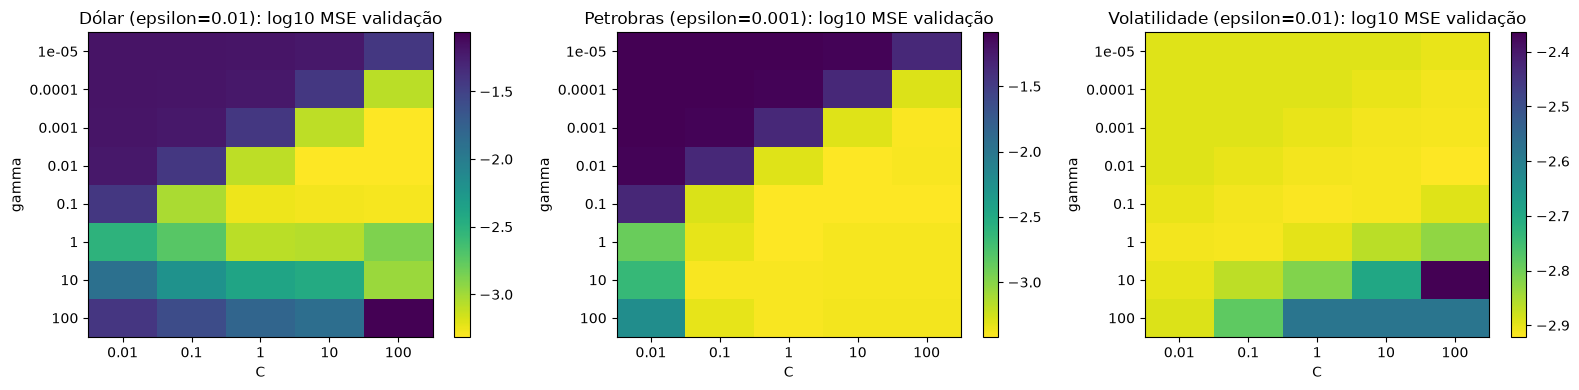

In [ ]:
# Mapa do MSE de validação (gamma x C), no melhor epsilon de cada série
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
for eixo, nome in zip(eixos, bases):
    parte = busca[busca["série"] == nome]
    eps = parte.loc[parte["MSE validação"].idxmin(), "epsilon"]
    mapa = parte[parte.epsilon == eps].pivot(index="gamma", columns="C", values="MSE validação")
    im = eixo.imshow(np.log10(mapa.values), cmap="viridis_r", aspect="auto")
    eixo.set_xticks(range(len(mapa.columns)), [f"{v:g}" for v in mapa.columns])
    eixo.set_yticks(range(len(mapa.index)), [f"{v:g}" for v in mapa.index])
    eixo.set_xlabel("C"); eixo.set_ylabel("gamma")
    eixo.set_title(f"{nome} (epsilon={eps:g}): log10 MSE validação")
    fig.colorbar(im, ax=eixo)
plt.tight_layout()

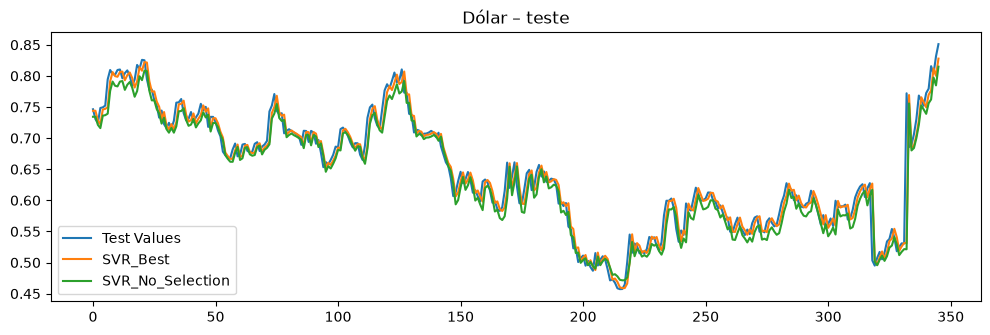

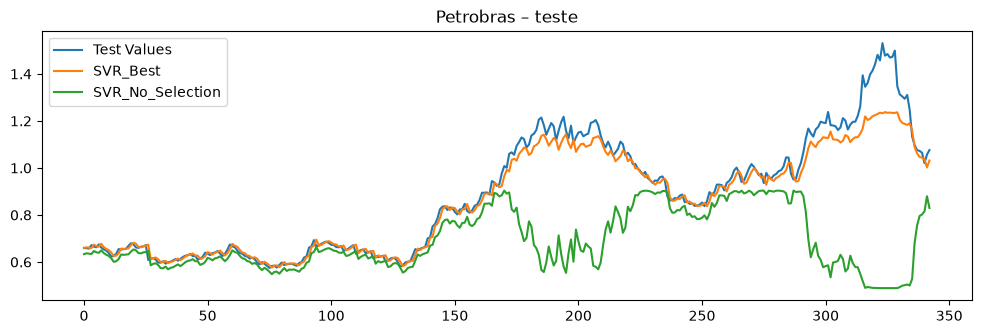

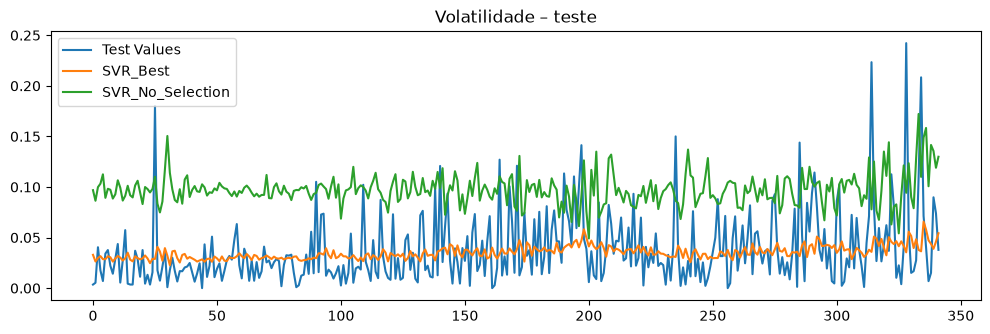

In [ ]:
# Gráfico do teste, como no exemplo do professor
for nome, (testTarget, predTest, predTestNoSelection) in curvas.items():
    plt.figure(figsize=(12, 3.5))
    plt.plot(testTarget)
    plt.plot(predTest)
    plt.plot(predTestNoSelection)
    plt.legend(["Test Values", "SVR_Best", "SVR_No_Selection"])
    plt.title(f"{nome} – teste")
    plt.show()

## Conclusões

Resultados com os dados até 13/11/2026.

**Melhores parâmetros (menor MSE na validação)**

| série | dimension | gamma | epsilon | C |
|---|---|---|---|---|
| Dólar | 1 | 0,01 | 0,01 | 100 |
| Petrobras | 1 | 1 | 0,001 | 1 |
| Volatilidade | 14 | 0,01 | 0,01 | 100 |

**A seleção de parâmetros vale a pena.** Nas três séries, o SVR ajustado erra bem menos no teste que o `SVR()` padrão:
- dólar: 0,00049 contra 0,00061;
- volatilidade: 0,00123 contra 0,00502 (4 vezes menos);
- Petrobras: 0,0033 contra 0,106 (32 vezes menos).

**Volatilidade**: o SVR ajustado é o **melhor modelo** do teste, ganhando do linear (0,00131) e do ingênuo (0,00215).

**Dólar**: o SVR ajustado empata com o linear e com o ingênuo (≈ 0,00049).

**Petrobras**: mesmo ajustado, o SVR erra **5 vezes mais** que o linear e o ingênuo no teste (0,0033 contra ≈ 0,00066), apesar de ter o melhor MSE na validação. O motivo é que **33% dos dias do teste ficam acima do maior preço do treino** (até 1,53 na escala normalizada). Com kernel RBF, o SVR não prevê valores fora da faixa que viu no treino, e a previsão fica "presa" no teto, como mostra o gráfico. Para a Petrobras vale testar outra forma de entrada, como a variação diária em vez do preço, ou um kernel linear.

> Referência para o relatório: o artigo de Alves et al. (2022) usa uma faixa mais larga, com `C` até 10⁴, `gamma` até 10³ e `epsilon` de 10⁻⁸ a 10⁻², e escolhe os parâmetros com PSO. Aqui usamos a mesma grade do exemplo da aula.